# Assignment 2 – Designing Automata for Real-Time Applications

**Applications:** Password Verification, Email Format Validation, and ATM PIN Verification

This notebook demonstrates three simplified finite-automata-based validators. Each section defines the accepted input pattern, implements a validator, displays a state diagram, and tests accepted and rejected examples.

> **Scope note:** These are format validators for an assignment demonstration. They do not authenticate users, confirm that an email account exists, or enforce external business rules.

## 1. Password Verification System

### Alphabet and language
The input alphabet is grouped into four useful character categories:

- `U`: uppercase English letter (`A–Z`)
- `L`: lowercase English letter (`a–z`)
- `D`: digit (`0–9`)
- `O`: another non-whitespace character

Whitespace is rejected. The accepted language contains passwords that:
1. have at least 8 characters,
2. contain at least one uppercase letter,
3. contain at least one lowercase letter, and
4. contain at least one digit.

The implementation tracks the state tuple `(length, uppercase_seen, lowercase_seen, digit_seen)`. The length counter is capped at 8 because the rule has a minimum length and no maximum length. This gives `9 × 2 × 2 × 2 = 72` tracking states, plus a rejecting trap state for whitespace.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import string
import pandas as pd

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
def password_dfa(password):
    length = 0
    upper = False
    lower = False
    digit = False

    for ch in password:
        if ch.isspace():
            return False, "DEAD"

        length = min(length + 1, 8)

        if ch in string.ascii_uppercase:
            upper = True
        elif ch in string.ascii_lowercase:
            lower = True
        elif ch in string.digits:
            digit = True

    final_state = (length, upper, lower, digit)

    accepted = length == 8 and upper and lower and digit
    return accepted, final_state

print(password_dfa("Abcd1234"))

(True, (8, True, True, True))


In [3]:
password_tests = [
    ("Abcd1234", True),
    ("Hello123A", True),
    ("PassWord9", True),
    ("Student1A", True),
    ("College5B", True),

    ("hello123", False),
    ("ABCDEFG1", False),
    ("abcdefghi", False),
    ("Abc123", False),
    ("12345678", False),
    ("Abcd 1234", False)
]

print("PASSWORD VERIFICATION RESULTS")

for password, expected in password_tests:
    result, state = password_dfa(password)
    status = "ACCEPTED" if result else "REJECTED"
    print(password, ":", status,
          "| Expected:", "ACCEPTED" if expected else "REJECTED",
          "| Correct:", result == expected)

PASSWORD VERIFICATION RESULTS
Abcd1234 : ACCEPTED | Expected: ACCEPTED | Correct: True
Hello123A : ACCEPTED | Expected: ACCEPTED | Correct: True
PassWord9 : ACCEPTED | Expected: ACCEPTED | Correct: True
Student1A : ACCEPTED | Expected: ACCEPTED | Correct: True
College5B : ACCEPTED | Expected: ACCEPTED | Correct: True
hello123 : REJECTED | Expected: REJECTED | Correct: True
ABCDEFG1 : REJECTED | Expected: REJECTED | Correct: True
abcdefghi : REJECTED | Expected: REJECTED | Correct: True
Abc123 : REJECTED | Expected: REJECTED | Correct: True
12345678 : REJECTED | Expected: REJECTED | Correct: True
Abcd 1234 : REJECTED | Expected: REJECTED | Correct: True


In [4]:
from itertools import product

password_states = list(product(
    range(9),
    [False, True],
    [False, True],
    [False, True]
))

accepting_password_states = [
    state for state in password_states
    if state[0] == 8 and state[1] and state[2] and state[3]
]

print("Tracking DFA states:", len(password_states))
print("Additional trap state: 1")
print("Total states including trap:", len(password_states) + 1)
print("Accepting states:", len(accepting_password_states))
print("Initial state:", (0, False, False, False))
print("Accepting condition: length=8, uppercase=True, lowercase=True, digit=True")

Tracking DFA states: 72
Additional trap state: 1
Total states including trap: 73
Accepting states: 1
Initial state: (0, False, False, False)
Accepting condition: length=8, uppercase=True, lowercase=True, digit=True


### Password DFA diagram and explanation

The full product DFA has 72 tracking states, so the diagram below is a compact overview rather than a drawing of every state. The tracking node represents the state tuple. At end of input, the password is accepted only if all four conditions are satisfied. A whitespace character moves the machine to the rejecting trap state.

**Limitations:** This policy checks only the stated format rules. It does not check password strength against common-password lists, leaked passwords, account identity, or multi-factor authentication.

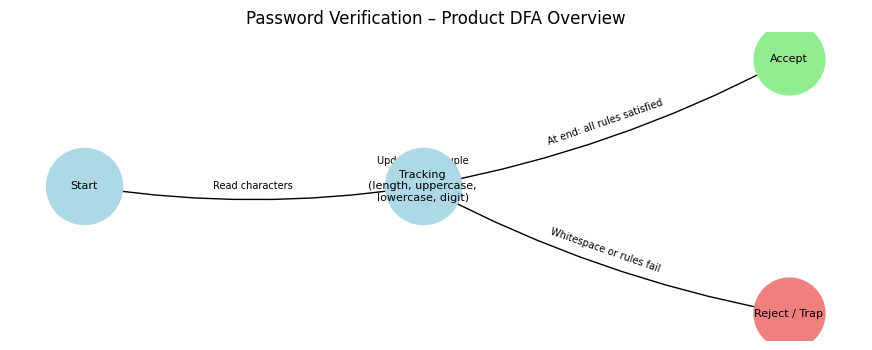

In [5]:
G = nx.DiGraph()
track = "Tracking\n(length, uppercase,\nlowercase, digit)"
G.add_edges_from([
    ("Start", track, {"label": "Read characters"}),
    (track, track, {"label": "Update state tuple"}),
    (track, "Accept", {"label": "At end: all rules satisfied"}),
    (track, "Reject / Trap", {"label": "Whitespace or rules fail"})
])

pos = {
    "Start": (0, 1),
    track: (2.5, 1),
    "Accept": (5.2, 2),
    "Reject / Trap": (5.2, 0)
}

plt.figure(figsize=(11, 4))
nx.draw_networkx_nodes(G, pos, nodelist=["Start", track],
                       node_color="lightblue", node_size=3000)
nx.draw_networkx_nodes(G, pos, nodelist=["Accept"],
                       node_color="lightgreen", node_size=2600)
nx.draw_networkx_nodes(G, pos, nodelist=["Reject / Trap"],
                       node_color="lightcoral", node_size=2600)
nx.draw_networkx_labels(G, pos, font_size=8)
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=18,
                       connectionstyle="arc3,rad=0.08")
nx.draw_networkx_edge_labels(G, pos,
    edge_labels=nx.get_edge_attributes(G, "label"), font_size=7)
plt.title("Password Verification – Product DFA Overview")
plt.axis("off")
plt.show()

## 2. Email Format Validator

### Alphabet and language
This validator recognizes a deliberately simplified email format:

- The local part before `@` must contain one or more alphanumeric characters.
- Exactly one `@` separates the local part and domain.
- The domain name before the final dot must contain one or more alphanumeric characters.
- The final top-level domain (TLD) must contain at least two alphabetic characters.

Examples such as `student@gmail.com` are accepted. This is a simplified subset of email syntax, not a complete implementation of every email-address standard.

In [6]:
def email_dfa(email):
    START = 0
    LOCAL = 1
    DOMAIN_START = 2
    DOMAIN = 3
    DOMAIN_DOT = 4
    TLD_ONE = 5
    TLD_VALID = 6
    DEAD = 7

    state = START

    for ch in email:
        if state == START:
            if ch.isascii() and ch.isalnum():
                state = LOCAL
            else:
                state = DEAD

        elif state == LOCAL:
            if ch.isascii() and ch.isalnum():
                state = LOCAL
            elif ch == "@":
                state = DOMAIN_START
            else:
                state = DEAD

        elif state == DOMAIN_START:
            if ch.isascii() and ch.isalnum():
                state = DOMAIN
            else:
                state = DEAD

        elif state == DOMAIN:
            if ch.isascii() and ch.isalnum():
                state = DOMAIN
            elif ch == ".":
                state = DOMAIN_DOT
            else:
                state = DEAD

        elif state == DOMAIN_DOT:
            if ch.isascii() and ch.isalpha():
                state = TLD_ONE
            else:
                state = DEAD

        elif state == TLD_ONE:
            if ch.isascii() and ch.isalpha():
                state = TLD_VALID
            else:
                state = DEAD

        elif state == TLD_VALID:
            if ch.isascii() and ch.isalpha():
                state = TLD_VALID
            else:
                state = DEAD

        elif state == DEAD:
            state = DEAD

    return state == TLD_VALID

In [7]:
email_tests = [
    ("student@gmail.com", True),
    ("abc@college.edu", True),
    ("user12@yahoo.in", True),
    ("test1@domain.org", True),
    ("hello@school.net", True),

    ("studentgmail.com", False),
    ("@gmail.com", False),
    ("abc@.com", False),
    ("abc@college", False),
    ("abc@domain.c", False),
    ("a@@domain.com", False)
]

print("EMAIL VALIDATION RESULTS")

for email, expected in email_tests:
    result = email_dfa(email)
    status = "ACCEPTED" if result else "REJECTED"
    print(email, ":", status,
          "| Expected:", "ACCEPTED" if expected else "REJECTED",
          "| Correct:", result == expected)

EMAIL VALIDATION RESULTS
student@gmail.com : ACCEPTED | Expected: ACCEPTED | Correct: True
abc@college.edu : ACCEPTED | Expected: ACCEPTED | Correct: True
user12@yahoo.in : ACCEPTED | Expected: ACCEPTED | Correct: True
test1@domain.org : ACCEPTED | Expected: ACCEPTED | Correct: True
hello@school.net : ACCEPTED | Expected: ACCEPTED | Correct: True
studentgmail.com : REJECTED | Expected: REJECTED | Correct: True
@gmail.com : REJECTED | Expected: REJECTED | Correct: True
abc@.com : REJECTED | Expected: REJECTED | Correct: True
abc@college : REJECTED | Expected: REJECTED | Correct: True
abc@domain.c : REJECTED | Expected: REJECTED | Correct: True
a@@domain.com : REJECTED | Expected: REJECTED | Correct: True


### Email DFA diagram and explanation

`START` reads the first local-part character. `LOCAL` loops over local-part alphanumeric characters and moves to `DOMAIN_START` on `@`. The domain states then require a domain name, a dot, and at least two alphabetic TLD characters. `TLD_VALID` is the accepting state. Invalid input from any state moves to `DEAD`, which loops on all further input.

**Limitations:** This simplified automaton does not support all valid email syntax (for example, dots or plus signs in the local part, and hyphens in domain labels). It checks syntax only; it cannot confirm that the mailbox exists or can receive messages.

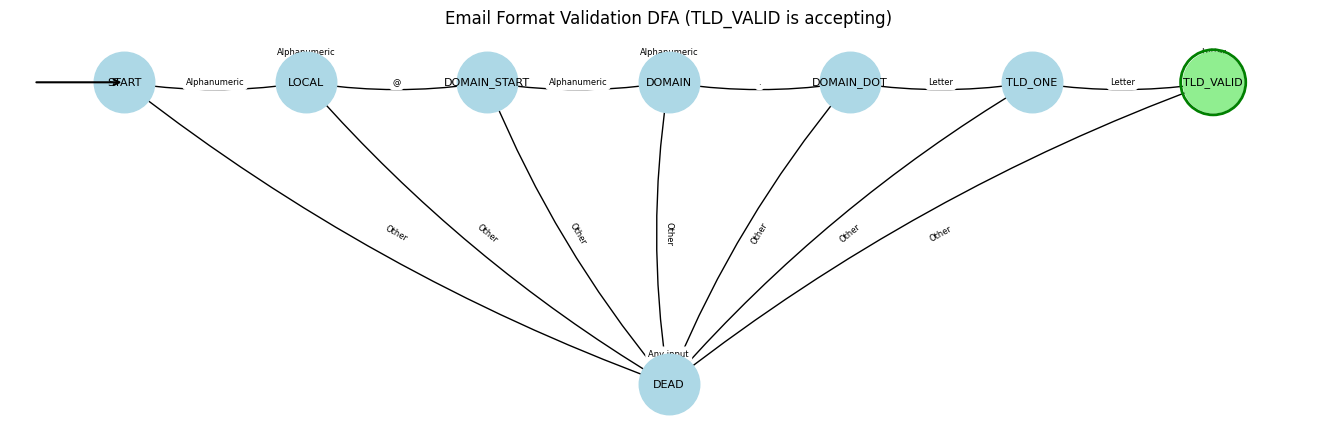

In [8]:
G = nx.DiGraph()
email_states = [
    "START", "LOCAL", "DOMAIN_START", "DOMAIN",
    "DOMAIN_DOT", "TLD_ONE", "TLD_VALID", "DEAD"
]
G.add_nodes_from(email_states)

email_edges = [
    ("START", "LOCAL", "Alphanumeric"),
    ("START", "DEAD", "Other"),
    ("LOCAL", "LOCAL", "Alphanumeric"),
    ("LOCAL", "DOMAIN_START", "@"),
    ("LOCAL", "DEAD", "Other"),
    ("DOMAIN_START", "DOMAIN", "Alphanumeric"),
    ("DOMAIN_START", "DEAD", "Other"),
    ("DOMAIN", "DOMAIN", "Alphanumeric"),
    ("DOMAIN", "DOMAIN_DOT", "."),
    ("DOMAIN", "DEAD", "Other"),
    ("DOMAIN_DOT", "TLD_ONE", "Letter"),
    ("DOMAIN_DOT", "DEAD", "Other"),
    ("TLD_ONE", "TLD_VALID", "Letter"),
    ("TLD_ONE", "DEAD", "Other"),
    ("TLD_VALID", "TLD_VALID", "Letter"),
    ("TLD_VALID", "DEAD", "Other"),
    ("DEAD", "DEAD", "Any input")
]

for source, target, label in email_edges:
    G.add_edge(source, target, label=label)

pos = {
    "START": (0, 1), "LOCAL": (2, 1),
    "DOMAIN_START": (4, 1), "DOMAIN": (6, 1),
    "DOMAIN_DOT": (8, 1), "TLD_ONE": (10, 1),
    "TLD_VALID": (12, 1), "DEAD": (6, -1)
}

plt.figure(figsize=(17, 5))
nx.draw_networkx_nodes(G, pos, nodelist=[s for s in email_states if s != "TLD_VALID"],
                       node_color="lightblue", node_size=1900)
nx.draw_networkx_nodes(G, pos, nodelist=["TLD_VALID"],
                       node_color="lightgreen", node_size=1900)
nx.draw_networkx_nodes(G, pos, nodelist=["TLD_VALID"],
                       node_color="none", edgecolors="green",
                       node_size=2200, linewidths=2)
nx.draw_networkx_labels(G, pos, font_size=8)
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=15,
                       connectionstyle="arc3,rad=0.08")
nx.draw_networkx_edge_labels(G, pos,
    edge_labels=nx.get_edge_attributes(G, "label"), font_size=6)
plt.annotate("", xy=(0, 1), xytext=(-1, 1),
             arrowprops=dict(arrowstyle="->", lw=1.5))
plt.title("Email Format Validation DFA (TLD_VALID is accepting)")
plt.axis("off")
plt.show()

## 3. ATM PIN Verification

### Alphabet and language
The input alphabet is divided into:
- `D`: a decimal digit (`0–9`)
- `O`: any non-digit character

The accepted language consists of strings containing **exactly four digits**. The machine uses states `q0` through `q4` to count the digits. Any non-digit, or any extra character after the fourth digit, moves to the `Dead` state. `q4` is the accepting state.

In [9]:
def atm_pin_dfa(pin):
    state = 0

    for ch in pin:
        if ch not in string.digits:
            state = "DEAD"
            break

        if state == "DEAD":
            break

        if state < 4:
            state += 1
        else:
            state = "DEAD"

    return state == 4

In [10]:
pin_tests = [
    ("1234", True),
    ("5678", True),
    ("2468", True),
    ("1357", True),
    ("9087", True),

    ("123", False),
    ("12345", False),
    ("12A4", False),
    ("ABCD", False),
    ("1 23", False)
]

print("ATM PIN VERIFICATION RESULTS")

for pin, expected in pin_tests:
    result = atm_pin_dfa(pin)
    status = "ACCEPTED" if result else "REJECTED"
    print(pin, ":", status,
          "| Expected:", "ACCEPTED" if expected else "REJECTED",
          "| Correct:", result == expected)

ATM PIN VERIFICATION RESULTS
1234 : ACCEPTED | Expected: ACCEPTED | Correct: True
5678 : ACCEPTED | Expected: ACCEPTED | Correct: True
2468 : ACCEPTED | Expected: ACCEPTED | Correct: True
1357 : ACCEPTED | Expected: ACCEPTED | Correct: True
9087 : ACCEPTED | Expected: ACCEPTED | Correct: True
123 : REJECTED | Expected: REJECTED | Correct: True
12345 : REJECTED | Expected: REJECTED | Correct: True
12A4 : REJECTED | Expected: REJECTED | Correct: True
ABCD : REJECTED | Expected: REJECTED | Correct: True
1 23 : REJECTED | Expected: REJECTED | Correct: True


### ATM PIN DFA diagram and explanation

For every digit, the machine moves one state to the right: `q0 → q1 → q2 → q3 → q4`. Any non-digit from `q0` to `q4` goes to `Dead`. Any extra input from `q4` also goes to `Dead`. The `Dead` state loops on all input. `q4` is the only accepting state.

**Limitations:** This DFA checks only that the input has exactly four digits. It does not compare the PIN with a stored PIN, identify an account, limit login attempts, or perform secure authentication.

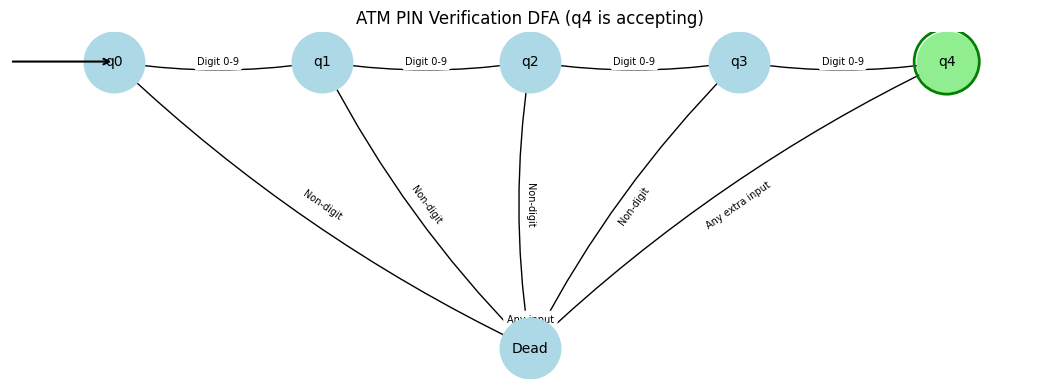

In [11]:
G = nx.DiGraph()
states = ["q0", "q1", "q2", "q3", "q4", "Dead"]
G.add_nodes_from(states)

edges = [
    ("q0", "q1", "Digit 0-9"),
    ("q1", "q2", "Digit 0-9"),
    ("q2", "q3", "Digit 0-9"),
    ("q3", "q4", "Digit 0-9"),
    ("q0", "Dead", "Non-digit"),
    ("q1", "Dead", "Non-digit"),
    ("q2", "Dead", "Non-digit"),
    ("q3", "Dead", "Non-digit"),
    ("q4", "Dead", "Any extra input"),
    ("Dead", "Dead", "Any input")
]
for source, target, label in edges:
    G.add_edge(source, target, label=label)

pos = {
    "q0": (0, 1), "q1": (2, 1), "q2": (4, 1),
    "q3": (6, 1), "q4": (8, 1), "Dead": (4, -1)
}

plt.figure(figsize=(13, 4.5))
nx.draw_networkx_nodes(G, pos, nodelist=["q0", "q1", "q2", "q3", "Dead"],
                       node_color="lightblue", node_size=1900)
nx.draw_networkx_nodes(G, pos, nodelist=["q4"],
                       node_color="lightgreen", node_size=1900)
nx.draw_networkx_nodes(G, pos, nodelist=["q4"],
                       node_color="none", edgecolors="green",
                       node_size=2200, linewidths=2)
nx.draw_networkx_labels(G, pos, font_size=10)
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=16,
                       connectionstyle="arc3,rad=0.08")
nx.draw_networkx_edge_labels(G, pos,
    edge_labels=nx.get_edge_attributes(G, "label"), font_size=7)
plt.annotate("", xy=(0, 1), xytext=(-1, 1),
             arrowprops=dict(arrowstyle="->", lw=1.5))
plt.title("ATM PIN Verification DFA (q4 is accepting)")
plt.axis("off")
plt.show()

## 4. Comparison: Syntax Validation and Semantic / Business Rules

A finite automaton is suitable when the rule can be expressed as a regular pattern and only a finite amount of state information is needed.

| Application | What the automaton checks | What needs additional processing |
|---|---|---|
| Password | Minimum length and required character categories | Password strength, breached-password checks, user identity, multi-factor authentication |
| Email | The simplified character and separator pattern defined above | Whether the mailbox exists, domain/mail-server checks, verification email |
| ATM PIN | Exactly four numeric characters | Matching the stored PIN, account status, attempt limits, secure authentication |

**Syntax validation** checks whether input follows a required format. **Semantic or business validation** checks whether the input is meaningful and permitted in the real application. A DFA can perform the first kind of check for these examples, but additional application logic is required for the second.

## 5. Combined Test Runner

The following cell runs every accepted and rejected example and reports the overall result. A passing test means the implementation agrees with the expected result for that test case; it does not prove that every possible input has been tested.

In [12]:
all_tests = [
    ("PASSWORD", password_tests, password_dfa),
    ("EMAIL", email_tests, email_dfa),
    ("ATM PIN", pin_tests, atm_pin_dfa)
]

total = 0
passed = 0

for application, tests, validator in all_tests:
    print("\\n", application, "VERIFICATION")

    for value, expected in tests:
        if application == "PASSWORD":
            result, _ = validator(value)
        else:
            result = validator(value)

        correct = result == expected
        total += 1
        passed += int(correct)

        print(value, ":", "ACCEPTED" if result else "REJECTED",
              "| Test:", "PASS" if correct else "FAIL")

print("\\n" + "=" * 45)
print("TOTAL TESTS:", total)
print("PASSED:", passed)
print("FAILED:", total - passed)
print("=" * 45)

\n PASSWORD VERIFICATION
Abcd1234 : ACCEPTED | Test: PASS
Hello123A : ACCEPTED | Test: PASS
PassWord9 : ACCEPTED | Test: PASS
Student1A : ACCEPTED | Test: PASS
College5B : ACCEPTED | Test: PASS
hello123 : REJECTED | Test: PASS
ABCDEFG1 : REJECTED | Test: PASS
abcdefghi : REJECTED | Test: PASS
Abc123 : REJECTED | Test: PASS
12345678 : REJECTED | Test: PASS
Abcd 1234 : REJECTED | Test: PASS
\n EMAIL VERIFICATION
student@gmail.com : ACCEPTED | Test: PASS
abc@college.edu : ACCEPTED | Test: PASS
user12@yahoo.in : ACCEPTED | Test: PASS
test1@domain.org : ACCEPTED | Test: PASS
hello@school.net : ACCEPTED | Test: PASS
studentgmail.com : REJECTED | Test: PASS
@gmail.com : REJECTED | Test: PASS
abc@.com : REJECTED | Test: PASS
abc@college : REJECTED | Test: PASS
abc@domain.c : REJECTED | Test: PASS
a@@domain.com : REJECTED | Test: PASS
\n ATM PIN VERIFICATION
1234 : ACCEPTED | Test: PASS
5678 : ACCEPTED | Test: PASS
2468 : ACCEPTED | Test: PASS
1357 : ACCEPTED | Test: PASS
9087 : ACCEPTED | Test

## 6. Demonstration and Submission Checklist

For a short demonstration:
1. Explain the alphabet and accepted language for each application.
2. Show each DFA diagram and identify its initial, accepting, and dead states.
3. Run the accepted and rejected examples.
4. Explain the limitations and distinguish syntax checks from business rules.

Before submitting:
- Run **Runtime → Run all** in Google Colab.
- Confirm the final test runner reports zero failures.
- Check that all three diagrams and their labels are visible.
- Save the notebook with a clear filename, such as `Assignment_2_Finite_Automata.ipynb`.
- Add your own name, class details, and any required cover information before submission.